# 06 · Diffusion Model Foundations: Learning to Denoise

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| **06** | **Diffusion** | **Learn to denoise** | **Stable, high-quality generation** | **Matches data, not *goals*; slow sampling** |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

The language-model thread generated one token at a time. Diffusion models generate by **reversing a noising
process**: start from pure Gaussian noise and repeatedly remove a little of it. The idea goes back to
[Sohl-Dickstein et al., 2015](https://arxiv.org/abs/1503.03585). [Ho et al., 2020](https://arxiv.org/abs/2006.11239) (DDPM) made it practical with a simple denoising loss, and [Song et al., 2020](https://arxiv.org/abs/2011.13456)
showed it is equivalent to learning the **score** $\nabla_x \log p_t(x)$ of the noised data. Within two years,
diffusion models beat GANs on image quality ([Dhariwal & Nichol, 2021](https://arxiv.org/abs/2105.05233)) and became the base of text-to-image systems
([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)).

This notebook builds the pieces every later notebook needs: the forward process, the $\varepsilon$- and
$v$-prediction objectives, DDIM sampling, and classifier-free guidance. We train on scikit-learn's 8×8
handwritten digits (1,797 images, no download), and score samples with a frozen **judge** CNN. The judge plays
two roles: FID's Inception network, supplying features for the metrics, and, in notebook 07, a reward model.

## Learning objectives

1. Write the forward process $q(x_t\mid x_0)$ and derive the denoising objective, in $\varepsilon$- and $v$-parameterisations.
2. Sample with DDIM ([Song et al., 2020](https://arxiv.org/abs/2010.02502)) and measure the quality vs number-of-steps trade-off.
3. Implement classifier-free guidance ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)) and measure its precision/coverage trade-off.
4. State the two limitations that motivate notebooks 07 and 08: diffusion models match the data, not a goal, and sampling is expensive.

**Runtime:** about 6 minutes on a laptop CPU.

train (1438, 64), test (359, 64); pixel range [-1, 1]


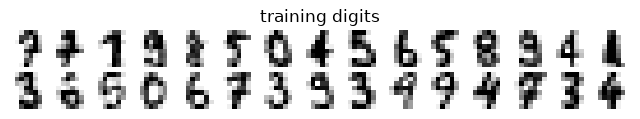

In [1]:
import sys, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
from ptlib import images, metrics, set_seed
from ptlib import diffusion as dfx
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()
print(f"train {tuple(Xtr.shape)}, test {tuple(Xte.shape)}; pixel range [{Xtr.min():.0f}, {Xtr.max():.0f}]")
fig, ax = plt.subplots(figsize=(8, 2)); images.show_grid(Xtr[:30], nrow=15, ax=ax, title="training digits"); plt.show()

## 1. The forward process

Fix a schedule $\bar\alpha_t$ decreasing from ≈1 to ≈0 over $t = 0..T-1$ ($T = 1000$; we use the cosine schedule of
[Nichol & Dhariwal, 2021](https://arxiv.org/abs/2102.09672)). Noising is available in closed form at any step:
$$q(x_t \mid x_0) = \mathcal{N}\big(\sqrt{\bar\alpha_t}\,x_0,\; (1-\bar\alpha_t)\,I\big) \quad\Longleftrightarrow\quad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\;\; \varepsilon\sim\mathcal{N}(0, I).$$

At $t = T-1$ almost nothing of $x_0$ is left. A generative model only has to learn to *undo* small steps of this.
We first watch it on 2-D data, where every distribution can be drawn.

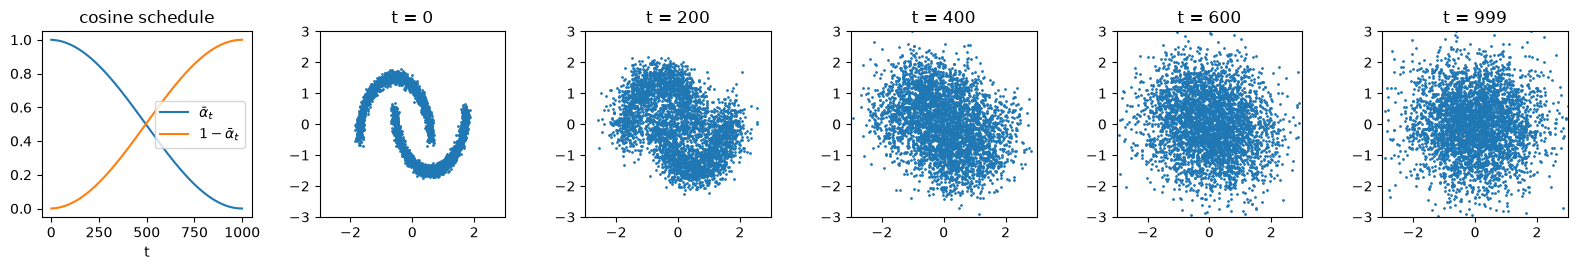

In [2]:
from sklearn.datasets import make_moons
moons = torch.tensor(make_moons(4000, noise=0.05, random_state=0)[0], dtype=torch.float32)
moons = (moons - moons.mean(0)) / moons.std(0)
fig, axes = plt.subplots(1, 6, figsize=(16, 2.8))
axes[0].plot(dfx.ALPHA_BAR.numpy(), label=r"$\bar\alpha_t$"); axes[0].plot((1 - dfx.ALPHA_BAR).numpy(), label=r"$1-\bar\alpha_t$")
axes[0].set_xlabel("t"); axes[0].legend(); axes[0].set_title("cosine schedule")
for ax, t in zip(axes[1:], [0, 200, 400, 600, 999]):
    xt = dfx.q_sample(moons, torch.full((len(moons),), t), torch.randn_like(moons))
    ax.scatter(*xt.T, s=1); ax.set_title(f"t = {t}"); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
fig.tight_layout(); plt.show()

## 2. The denoising objective

DDPM ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)) trains a network to predict the noise that was added:
$$\mathcal{L}_\varepsilon(\theta) = \mathbb{E}_{x_0, t, \varepsilon}\,\big\|\varepsilon_\theta(x_t, t) - \varepsilon\big\|^2.$$
This is a reweighted variational bound (Sohl-Dickstein's ELBO), and it is also **denoising score matching**:
$\varepsilon_\theta(x_t, t) \approx -\sqrt{1-\bar\alpha_t}\,\nabla_{x_t}\log p_t(x_t)$, so the network learns which way
is "towards the data" at every noise level ([Song et al., 2020](https://arxiv.org/abs/2011.13456)).

**$v$-prediction** ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)) predicts $v = \sqrt{\bar\alpha_t}\,\varepsilon - \sqrt{1-\bar\alpha_t}\,x_0$ instead. It is
the same information, but it stays well-scaled at both ends of the schedule, where $\varepsilon$-prediction must
recover $x_0$ from a tiny signal. Either output converts to an estimate $\hat x_0$ of the clean data. The training
loop is the pretraining loop from notebook 01, with a different target:

In [3]:
src = inspect.getsource(dfx.train_diffusion)
print(src[src.index("    for step in range(steps):"):src.index("        losses.append")])

    for step in range(steps):
        idx = torch.randint(0, len(X), (batch,))
        x0, c = X[idx], y[idx].clone()
        c[torch.rand(batch) < p_uncond] = NULL
        t = torch.randint(0, T, (batch,))
        eps = torch.randn_like(x0)
        xt = q_sample(x0, t, eps)
        target = eps if pred == "eps" else v_target(x0, t, eps)
        loss = F.mse_loss(model(xt, t, c), target)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); ema.update(model)



step   1000  loss 0.9308  (7s)
step   2000  loss 0.8884  (15s)
step   3000  loss 0.8727  (22s)


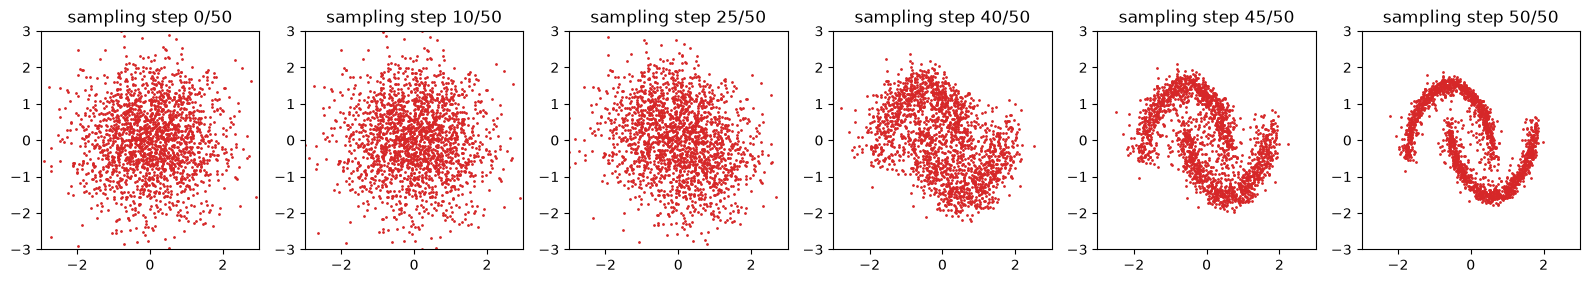

In [4]:
set_seed(0)
toy = dfx.MLPDenoiser(d_in=2, width=128, depth=3)
null = torch.full((len(moons),), dfx.NULL)                       # unconditional: every label is NULL
toy_ema, toy_loss = dfx.train_diffusion(toy, moons, null, steps=3000, batch=256, lr=2e-3, p_uncond=0.0, log_every=1000)
set_seed(1)
x, traj = dfx.sample_ddim(toy_ema, torch.full((2000,), dfx.NULL), steps=50, return_traj=True, clip=False)
fig, axes = plt.subplots(1, 6, figsize=(16, 2.8))
for ax, k in zip(axes, [0, 10, 25, 40, 45, 50]):
    ax.scatter(*traj[k].T, s=1, c="tab:red"); ax.set_title(f"sampling step {k}/50")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
fig.tight_layout(); plt.show()

## 3. Sampling with DDIM

DDPM sampling simulates the reverse Markov chain one step at a time, which takes all 1,000 steps. **DDIM**
([Song et al., 2020](https://arxiv.org/abs/2010.02502)) uses the same trained network but a non-Markovian reverse process that can skip steps.
From $x_t$, predict $\hat x_0$ and $\hat\varepsilon$, then jump to an earlier time $s$:
$$x_s = \sqrt{\bar\alpha_s}\,\hat x_0 + \sqrt{1-\bar\alpha_s-\sigma^2}\,\hat\varepsilon + \sigma z, \qquad z \sim \mathcal{N}(0, I).$$

With $\sigma = 0$ ("$\eta = 0$") sampling is a **deterministic** map from noise to data, a discretised ODE. With
$\eta = 1$ it is the stochastic DDPM-like sampler. The deterministic version is what later makes distillation
(notebook 08) and flow matching (notebook 09) possible.

## 4. Training on digits: ε- vs v-prediction

The denoiser is a 1.4M-parameter residual MLP that takes the noisy image (64 numbers), the timestep and a class
label. During training the label is replaced by NULL 10% of the time, so the same network is also an
unconditional model. Section 6 needs this.

real-data reference row: {'model': 'real data', 'fd': 3.322, 'precision': 0.969, 'coverage': 0.969, 'nn_ratio': 1.02, 'nfe': 0, 'judge_acc': 0.981}
eps-prediction trained in 102s
v-prediction trained in 105s


,fd,precision,coverage,nn_ratio,nfe,judge_acc
model,,,,,,
real data,3.322,0.969,0.969,1.020,0,0.981
"eps-pred, DDIM-10",7.986,0.953,0.916,0.945,10,0.972
"eps-pred, DDIM-50",6.695,0.950,0.928,0.938,50,0.972
"v-pred, DDIM-10",7.415,0.983,0.944,0.928,10,0.989
"v-pred, DDIM-50",6.126,0.981,0.953,0.932,50,0.989


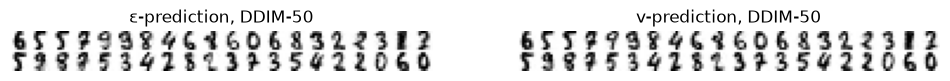

In [5]:
judge = images.get_judge()
sc = metrics.ImageScorecard(judge, Xtr, Xte, yte)
print("real-data reference row:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in sc.real_baseline().items()})
models = {}
for pred in ["eps", "v"]:
    t0 = time.time()
    models[pred], _ = dfx.train_diffusion(dfx.MLPDenoiser(), Xtr, ytr, **{**dfx.DIFF_KW, "pred": pred}, log_every=0)
    print(f"{pred}-prediction trained in {time.time() - t0:.0f}s")
import os
from ptlib import CKPT_DIR
torch.save(models["v"].state_dict(), os.path.join(CKPT_DIR, "diffusion_base.pt"))    # base model for notebooks 07-08
labels = yte.clone()                                        # request the same class mix as the test set
samples = {}
for pred, m in models.items():
    for steps in [10, 50]:
        set_seed(0)
        samples[(pred, steps)] = dfx.sample_ddim(m, labels, steps=steps, pred=pred)
        sc.evaluate(samples[(pred, steps)], f"{pred}-pred, DDIM-{steps}", labels=labels, nfe=steps)
display(sc.table().round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6))
images.show_grid(samples[("eps", 50)][:40], nrow=20, ax=axes[0], title="ε-prediction, DDIM-50")
images.show_grid(samples[("v", 50)][:40], nrow=20, ax=axes[1], title="v-prediction, DDIM-50")
plt.show()

**Reading the scorecard.** FD is a Fréchet distance in the judge's feature space ("FID-like"; [Heusel et al., 2017](https://arxiv.org/abs/1706.08500)).
Precision and coverage ([Naeem et al., 2020](https://arxiv.org/abs/2002.09797)) separate quality from diversity. `nn_ratio` compares each sample's nearest
training image with its nearest test image: values near 1 mean the model is not copying its training set. The
**real data** row is the floor: two finite samples of the same distribution do not have FD 0. Both
parameterisations produce recognisable digits; compare their rows above, at 10 and at 50 steps.

## 5. Quality vs number of steps

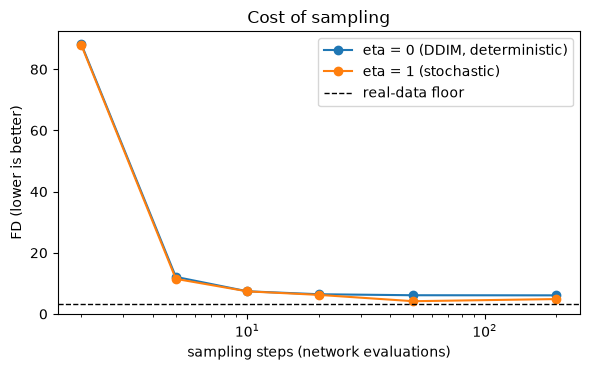

,steps,eta,fd,precision,coverage
0,2,0.0,88.207,0.401,0.047
1,2,1.0,87.868,0.409,0.050
2,5,0.0,12.126,0.972,0.933
3,5,1.0,11.478,0.978,0.925
4,10,0.0,7.415,0.983,0.944
5,10,1.0,7.398,1.000,0.978
6,20,0.0,6.451,0.981,0.953
7,20,1.0,6.243,0.969,0.969
8,50,0.0,6.126,0.981,0.953
9,50,1.0,4.177,0.981,0.967


In [6]:
nfe_rows = []
for steps in [2, 5, 10, 20, 50, 200]:
    for eta in [0.0, 1.0]:
        set_seed(0)
        s = dfx.sample_ddim(models["v"], labels, steps=steps, eta=eta)
        r = sc.evaluate(s, f"v-pred, {steps} steps, eta={eta:g}", labels=labels, nfe=steps)
        nfe_rows.append(dict(steps=steps, eta=eta, fd=r["fd"], precision=r["precision"], coverage=r["coverage"]))
nfe_df = pd.DataFrame(nfe_rows)
fig, ax = plt.subplots(figsize=(6, 3.8))
for eta, g in nfe_df.groupby("eta"):
    ax.semilogx(g.steps, g.fd, "o-", label=f"eta = {eta:g} ({'DDIM, deterministic' if eta == 0 else 'stochastic'})")
ax.axhline(sc.rows[0]["fd"], ls="--", c="k", lw=1, label="real-data floor")
ax.set_xlabel("sampling steps (network evaluations)"); ax.set_ylabel("FD (lower is better)"); ax.legend(); ax.set_title("Cost of sampling")
fig.tight_layout(); plt.show()
display(nfe_df.round(3))

Below about five steps both samplers collapse. Between 5 and 20 steps they are close. With many steps the
**stochastic** sampler reaches a lower FD: fresh noise at every step corrects errors that a deterministic
trajectory carries all the way to the end ([Karras et al., 2022](https://arxiv.org/abs/2206.00364) analyse this trade-off). The deterministic sampler's
advantage is different: it is a *fixed map* from noise to image, which is what distillation in notebook 08 needs.
Either way, good samples cost tens of network evaluations, where a GAN or a VAE needs one.

## 6. Classifier-free guidance

To make samples *more* class-typical, [Dhariwal & Nichol, 2021](https://arxiv.org/abs/2105.05233) added the gradient of a noisy-image classifier
to the score ("classifier guidance"). **Classifier-free guidance** ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)) gets the same effect from the
conditional/unconditional pair that a single network learns when labels are randomly dropped:
$$\tilde v = (1 + w)\, v_\theta(x_t, t, c) - w\, v_\theta(x_t, t, \varnothing).$$
This extrapolates away from the unconditional prediction. It costs two network evaluations per step, and nearly
every text-to-image model ships with it.

,w,fd,precision,coverage,judge_acc,mean_ink
0,0.0,6.126,0.981,0.953,0.989,0.307
1,0.5,3.883,0.992,0.955,1.000,0.311
2,1.0,3.552,0.992,0.942,1.000,0.313
3,2.0,3.759,0.994,0.936,1.000,0.315
4,4.0,4.499,0.983,0.925,1.000,0.317
5,8.0,7.616,0.955,0.827,0.992,0.317


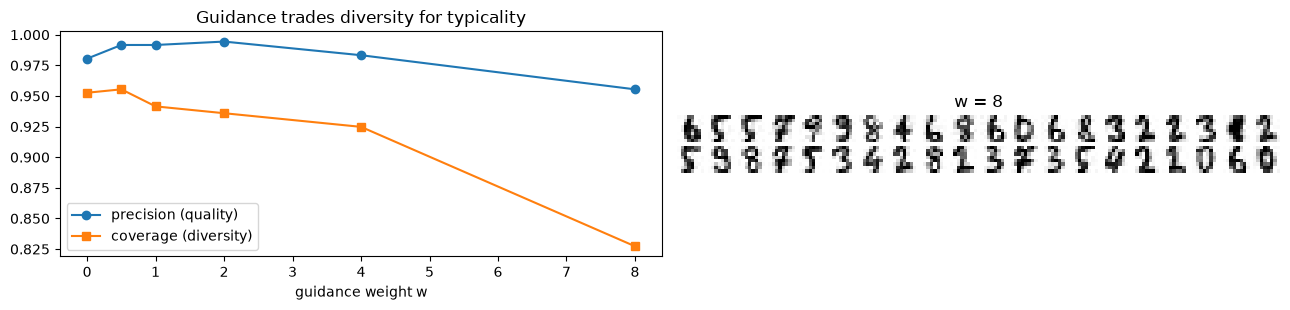

In [7]:
cfg_rows = []
for w in [0.0, 0.5, 1.0, 2.0, 4.0, 8.0]:
    set_seed(0)
    s = dfx.sample_ddim(models["v"], labels, steps=50, w=w)
    r = sc.evaluate(s, f"v-pred, DDIM-50, guidance w={w:g}", labels=labels, nfe=100 if w else 50)
    cfg_rows.append(dict(w=w, **{k: r[k] for k in ["fd", "precision", "coverage", "judge_acc"]}, mean_ink=float(((s + 1) / 2).mean())))
    if w == 8.0:
        s8 = s
cfg = pd.DataFrame(cfg_rows); display(cfg.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
axes[0].plot(cfg.w, cfg.precision, "o-", label="precision (quality)"); axes[0].plot(cfg.w, cfg.coverage, "s-", label="coverage (diversity)")
axes[0].set_xlabel("guidance weight w"); axes[0].legend(); axes[0].set_title("Guidance trades diversity for typicality")
images.show_grid(s8[:40], nrow=20, ax=axes[1], title="w = 8")
fig.tight_layout(); plt.show()

Moderate guidance ($w \approx 1$) gives the lowest FD and every sample is recognised by the judge. Beyond that,
coverage falls steadily and FD rises again. Samples become more typical of their class and less varied, until
whole modes of handwriting go missing at $w = 8$.

## 7. What diffusion training cannot do

Diffusion training is **maximum likelihood** (a bound on it), just like pretraining in notebook 01. The model
learns to reproduce its training distribution, and nothing else. Suppose we want **bold** digits: thick strokes,
which are rare in this dataset. The best the base model can do is the boldness of its data.

mean ink: training data 0.306 | base model samples 0.307 | bold target 0.703


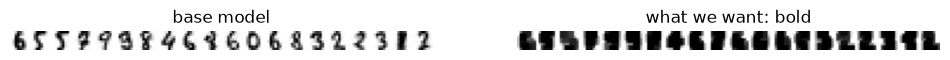

In [8]:
ink = lambda x: ((x.clamp(-1, 1) + 1) / 2).mean(1)                   # fraction of 'ink' per image, in [0, 1]
set_seed(0); base_s = dfx.sample_ddim(models["v"], labels, steps=50)
bold_real = images.bold(Xte)
print(f"mean ink: training data {ink(Xtr).mean():.3f} | base model samples {ink(base_s).mean():.3f} | bold target {ink(bold_real).mean():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 2.4))
images.show_grid(base_s[:20], nrow=20, ax=axes[0], title="base model"); images.show_grid(bold_real[:20], nrow=20, ax=axes[1], title="what we want: bold")
plt.show()

Two limitations, then, and the next two notebooks take one each:

1. **The model matches the data, not a goal.** Steering it toward "bold", "aesthetic" or "matches the prompt" needs post-training. Notebook 07 adapts the RLHF and DPO ideas from notebooks 02-05 to denoisers.
2. **Sampling is expensive.** Tens of network evaluations per image. Notebook 08 distils the sampler into a few steps.

## 8. Scorecard

In [9]:
keep = ["real data", "eps-pred, DDIM-50", "v-pred, DDIM-10", "v-pred, DDIM-50", "v-pred, DDIM-50, guidance w=1", "v-pred, DDIM-50, guidance w=4"]
t = sc.table().loc[keep].reset_index()
t["family"] = "image"
metrics.append_rows(t.to_dict("records"), "06_diffusion")
display(metrics.load_scorecard().query("family == 'image'")[["notebook", "model", "fd", "precision", "coverage", "judge_acc", "nn_ratio", "nfe"]].round(3))

,notebook,model,fd,precision,coverage,judge_acc,nn_ratio,nfe
25,06_diffusion,real data,3.322,0.969,0.969,0.981,1.020,0.0
26,06_diffusion,"eps-pred, DDIM-50",6.695,0.950,0.928,0.972,0.938,50.0
27,06_diffusion,"v-pred, DDIM-10",7.415,0.983,0.944,0.989,0.928,10.0
28,06_diffusion,"v-pred, DDIM-50",6.126,0.981,0.953,0.989,0.932,50.0
29,06_diffusion,"v-pred, DDIM-50, guidance w=1",3.552,0.992,0.942,1.000,0.904,100.0
30,06_diffusion,"v-pred, DDIM-50, guidance w=4",4.499,0.983,0.925,1.000,0.890,100.0


## Challenge Problem 1: Classifier guidance with the judge

Implement **classifier guidance** ([Dhariwal & Nichol, 2021](https://arxiv.org/abs/2105.05233)) with the judge. At each DDIM step, compute $\hat x_0$,
take the gradient $g = \nabla_{x_t}\log p_\text{judge}(c \mid \hat x_0)$, and shift the noise estimate
$\hat\varepsilon \leftarrow \hat\varepsilon - s\sqrt{1-\bar\alpha_t}\, g$. (The judge was trained on clean images, so it is
applied to $\hat x_0$ rather than $x_t$.) Sample with $s \in \{0, 2, 8\}$ and report judge accuracy and FD. Why might
the judge's accuracy be a misleading measure of success here?

In [10]:
# Start your code here

### Challenge Problem 1 Solution

In [11]:
import torch.nn.functional as F, math
def sample_cg(model, labels, scale, steps=50):
    x = torch.randn(len(labels), 64); ts = dfx.ddim_timesteps(steps)
    for i, t in enumerate(ts):
        tt = torch.full((len(labels),), int(t))
        x = x.detach().requires_grad_(True)
        x0, eps = dfx.to_x0_eps(model(x, tt, labels), x, tt)
        g = torch.autograd.grad(F.log_softmax(judge(x0.clamp(-1, 1)), -1)[torch.arange(len(labels)), labels].sum(), x)[0]
        ab = dfx.ALPHA_BAR[int(t)]
        eps = eps - scale * math.sqrt(1 - ab) * g
        x0 = ((x - math.sqrt(1 - ab) * eps) / math.sqrt(ab)).clamp(-1, 1)
        if i == len(ts) - 1:
            x = x0
        else:
            ab_s = dfx.ALPHA_BAR[int(ts[i + 1])]
            x = math.sqrt(ab_s) * x0 + math.sqrt(1 - ab_s) * (x - math.sqrt(ab) * x0) / math.sqrt(1 - ab)
    return x.detach()
for s in [0, 2, 8]:
    set_seed(0); r = sc.evaluate(sample_cg(models["v"], labels, s), f"classifier guidance s={s}", labels=labels)
    print(f"s={s}: judge acc {r['judge_acc']:.3f}  FD {r['fd']:.2f}  precision {r['precision']:.3f}  coverage {r['coverage']:.3f}")
# The judge both guides and grades: large s can produce images that exploit the judge (high accuracy, unusual
# pixels) - the same reward-hacking failure as notebook 03, which is why we also check FD and coverage.

s=0: judge acc 0.989  FD 6.13  precision 0.981  coverage 0.953
s=2: judge acc 1.000  FD 5.70  precision 0.981  coverage 0.942
s=8: judge acc 1.000  FD 5.46  precision 0.989  coverage 0.947


## Challenge Problem 2: Memorisation with a tiny dataset

Train the same denoiser on only the first 100 training images for 4,000 steps, sample 359 digits and compare its
`nn_ratio` with the full model's. What does a value well below 1 mean, and why is memorisation a concern for large
diffusion models trained on web images?

In [12]:
# Start your code here

### Challenge Problem 2 Solution

In [13]:
small, _ = dfx.train_diffusion(dfx.MLPDenoiser(), Xtr[:100], ytr[:100], steps=4000, batch=100, log_every=0)
set_seed(0); r = sc.evaluate(dfx.sample_ddim(small, labels, steps=50), "trained on 100 images", labels=labels)
print(f"nn_ratio: 100-image model {r['nn_ratio']:.3f} vs full model {sc.table().loc['v-pred, DDIM-50', 'nn_ratio']:.3f}")
# Note that the scorecard's nn_ratio compares against a random subset of the full training split, so for this model
# also check the distance to its own 100 training images:
set_seed(0); s = dfx.sample_ddim(small, labels, steps=50)
print("median distance to nearest of its 100 training images:", torch.cdist(s, Xtr[:100]).min(1).values.median().item(),
      "| between real test images and those 100:", torch.cdist(Xte, Xtr[:100]).min(1).values.median().item())
# Samples far closer to training images than real held-out images are = copies. Large text-to-image models have been
# shown to reproduce some training images, which raises privacy and copyright questions.

nn_ratio: 100-image model 0.916 vs full model 0.932
median distance to nearest of its 100 training images: 0.9833863377571106 | between real test images and those 100: 2.907425880432129


## Final summary

* A diffusion model learns to reverse a fixed noising process. Its training loss is a regression onto the added noise (or onto $v$), equivalent to score matching.
* DDIM turns the same network into a deterministic noise-to-data map that can skip steps. Quality still degrades below a few tens of steps.
* Classifier-free guidance trades diversity for class typicality with one extra network evaluation per step.
* Like a pretrained LM, a diffusion model matches its data. Steering it toward a goal is post-training (notebook 07), and making it fast is distillation (notebook 08).

## References

* Jascha Sohl-Dickstein, Eric A. Weiss, Niru Maheswaranathan et al. (2015). **Deep Unsupervised Learning using Nonequilibrium Thermodynamics**. arXiv:1503.03585. [arxiv.org/abs/1503.03585](https://arxiv.org/abs/1503.03585)
* Jonathan Ho, Ajay Jain, Pieter Abbeel (2020). **Denoising Diffusion Probabilistic Models**. arXiv:2006.11239. [arxiv.org/abs/2006.11239](https://arxiv.org/abs/2006.11239)
* Yang Song, Jascha Sohl-Dickstein, Diederik P. Kingma et al. (2020). **Score-Based Generative Modeling through Stochastic Differential Equations**. arXiv:2011.13456. [arxiv.org/abs/2011.13456](https://arxiv.org/abs/2011.13456)
* Jiaming Song, Chenlin Meng, Stefano Ermon (2020). **Denoising Diffusion Implicit Models**. arXiv:2010.02502. [arxiv.org/abs/2010.02502](https://arxiv.org/abs/2010.02502)
* Alex Nichol, Prafulla Dhariwal (2021). **Improved Denoising Diffusion Probabilistic Models**. arXiv:2102.09672. [arxiv.org/abs/2102.09672](https://arxiv.org/abs/2102.09672)
* Prafulla Dhariwal, Alex Nichol (2021). **Diffusion Models Beat GANs on Image Synthesis**. arXiv:2105.05233. [arxiv.org/abs/2105.05233](https://arxiv.org/abs/2105.05233)
* Jonathan Ho, Tim Salimans (2022). **Classifier-Free Diffusion Guidance**. arXiv:2207.12598. [arxiv.org/abs/2207.12598](https://arxiv.org/abs/2207.12598)
* Tim Salimans, Jonathan Ho (2022). **Progressive Distillation for Fast Sampling of Diffusion Models**. arXiv:2202.00512. [arxiv.org/abs/2202.00512](https://arxiv.org/abs/2202.00512)
* Robin Rombach, Andreas Blattmann, Dominik Lorenz et al. (2021). **High-Resolution Image Synthesis with Latent Diffusion Models**. arXiv:2112.10752. [arxiv.org/abs/2112.10752](https://arxiv.org/abs/2112.10752)
* Tero Karras, Miika Aittala, Timo Aila et al. (2022). **Elucidating the Design Space of Diffusion-Based Generative Models**. arXiv:2206.00364. [arxiv.org/abs/2206.00364](https://arxiv.org/abs/2206.00364)
* Martin Heusel, Hubert Ramsauer, Thomas Unterthiner et al. (2017). **GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium**. arXiv:1706.08500. [arxiv.org/abs/1706.08500](https://arxiv.org/abs/1706.08500)
* Muhammad Ferjad Naeem, Seong Joon Oh, Youngjung Uh et al. (2020). **Reliable Fidelity and Diversity Metrics for Generative Models**. arXiv:2002.09797. [arxiv.org/abs/2002.09797](https://arxiv.org/abs/2002.09797)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).